# Headless image registration: chaining Fractal tasks

This notebook aligns the imaging cycles of a multiplexed OME-Zarr plate with three [Fractal](https://fractal-analytics-platform.github.io/) tasks from the `fractal-tasks-core` package, run from Python with the API of `workflow_tasks_core`:

1. **Calculate Registration (image-based)** finds the shift between each cycle and the reference cycle.
2. **Find Registration Consensus** finds the region all cycles share.
3. **Apply Registration to Image** shifts the images and crops them to that region.

Each task works on what the previous one wrote into the OME-Zarr. After a run, `task.zarr_urls` lists the images to continue with, so it is passed straight to the next task.

The [segmentation example](segmentation.ipynb) covers the basics (catalog, installing, arguments, outputs) in more detail.

**Requirements**
- `pixi` on your `PATH` (or in `~/.pixi/bin`). Each task package runs in its own pixi environment.
- A kernel with `napari-workflow-tasks` installed, e.g. the repository's pixi environment (`pixi run python -m ipykernel install --user --name napari-workflow-tasks`).
- The example dataset `220605_151046_mip.zarr`, unzipped: one well (`C/02`) imaged in two cycles, with DAPI in both. Image `0` is cycle 0 (the reference), image `1` is cycle 1.

## Settings

In [11]:
from pathlib import Path

PLATE = Path.home() / "Downloads" / "220605_151046_mip.zarr"
WAVELENGTH = "A04_C01"  # the DAPI channel, imaged in both cycles

The tasks write into this OME-Zarr: registration results go into its ROI tables, and the last task **replaces the image data with the aligned images**. To start over with the unaligned images, unzip the dataset again.

## Get the task package

In [12]:
from workflow_tasks_core import Catalog

pkg = Catalog().package("fractal-tasks-core")
pkg.install()
print(pkg)
print("Tasks:", pkg.tasks)

System requirements: {'macos': '26.7.1'} (on the platform entry)
Installing fractal-tasks-core==2.1.0 from the cached install recipe (pixi.lock, --frozen)
✔ The default environment has been installed.
Caching the environment's native libraries
Native libraries: 501 found, 0 linked to the cache, 0 new in the cache, 501 already linked, 0 skipped (0.1s)
Import check skipped: it passed for this exact environment
Installed fractal-tasks-core==2.1.0 at /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/fractal_tasks_core (from the package's pixi.lock)
fractal-tasks-core 2.1.0
Tasks: ['Project Image (HCS Plate)', 'Project Image', 'Illumination Correction', 'Threshold Segmentation', 'Measure Features', 'Calculate Registration (image-based)', 'Find Registration Consensus', 'Apply Registration to Image', 'Import OME-Zarr']


In [13]:
calculate = pkg.task("Calculate Registration (image-based)")
consensus = pkg.task("Find Registration Consensus")
apply_registration = pkg.task("Apply Registration to Image")

The first two are *compound* tasks: a setup step runs once on all images (here, it pairs each cycle with the reference cycle of its well), then a compute step runs on each image. `help()` lists the arguments of each step. `run()` takes them all as keyword arguments and gives each step its own.

In [14]:
calculate.help()

Calculate Registration (image-based) (fractal-tasks-core 2.1.0, compound)
Computes image-based registration transformations for acquisitions in HCS OME-Zarr datasets. Processes images grouped by well, under the assumption that each well contains one image per acquisition. Calculates transformations for specified regions of interest (ROIs) and stores the results in the…
https://fractal-analytics-platform.github.io/fractal-tasks-core

Setup step (runs once on all images)

optional
  reference_acquisition        int = 0  Which acquisition to register against. Needs to match the acquisition metadata in the OME-Zarr image.

Compute step (runs once per image)

required
  wavelength_id                str  Wavelength that will be used for image-based registration; e.g. `A01_C01` for Yokogawa, `C01` for MD.

optional
  method                       RegistrationMethod = 'phase_cross_correlation'  Method to use for image registration. The available methods are `phase_cross_correlation` (scikit-ima

## 1. Calculate the shifts

`run()` takes the whole plate: it runs the task on all images of all its wells. The images are small, so the full resolution (`level_path="0"`) is used instead of the default `"2"`.

In [15]:
calculate.run(PLATE, wavelength_id=WAVELENGTH, level_path="0")
calculate.zarr_urls

=== setup on 2 image(s)
$ /opt/homebrew/bin/pixi run --frozen --manifest-path /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/pyproject.toml python /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/fractal_tasks_core/init_image_based_registration.py --args-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Calculate Registration (image-based)/setup.args.json --out-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Calculate Registration (image-based)/setup.out.json
2026-11-05 15:13:33,389; run_fractal_task; INFO; START init_image_based_registration task
2026-11-05 15:13:33,389; init_image_based_registration; INFO; Running `init_image_based_registration` for zarr_urls=['/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/0', '/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/1']
2026-11-05 15:13:33,391; init_image_based_registration; INFO; Fou

['/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/0',
 '/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/1']

The task added the shift of each field of view (FOV) to the image's `FOV_ROI_table` (`translation_x`, `translation_y`, `translation_z`, in micrometers). The reference cycle has no shift; cycle 1 is shifted against it:

In [16]:
from ngio import open_ome_zarr_container

shift_columns = ["translation_x", "translation_y", "translation_z"]
cycle_1 = calculate.zarr_urls[1]
open_ome_zarr_container(cycle_1).get_table("FOV_ROI_table").dataframe[shift_columns]

,translation_x,translation_y,translation_z
FieldIndex,,,
FOV_7,-36.616667,9.966667,0.0


### Before: the cycles in napari

`show()` opens a run's images in napari. Showing cycle 0 in green and cycle 1 in magenta makes the shift visible: where the nuclei overlap they are white.

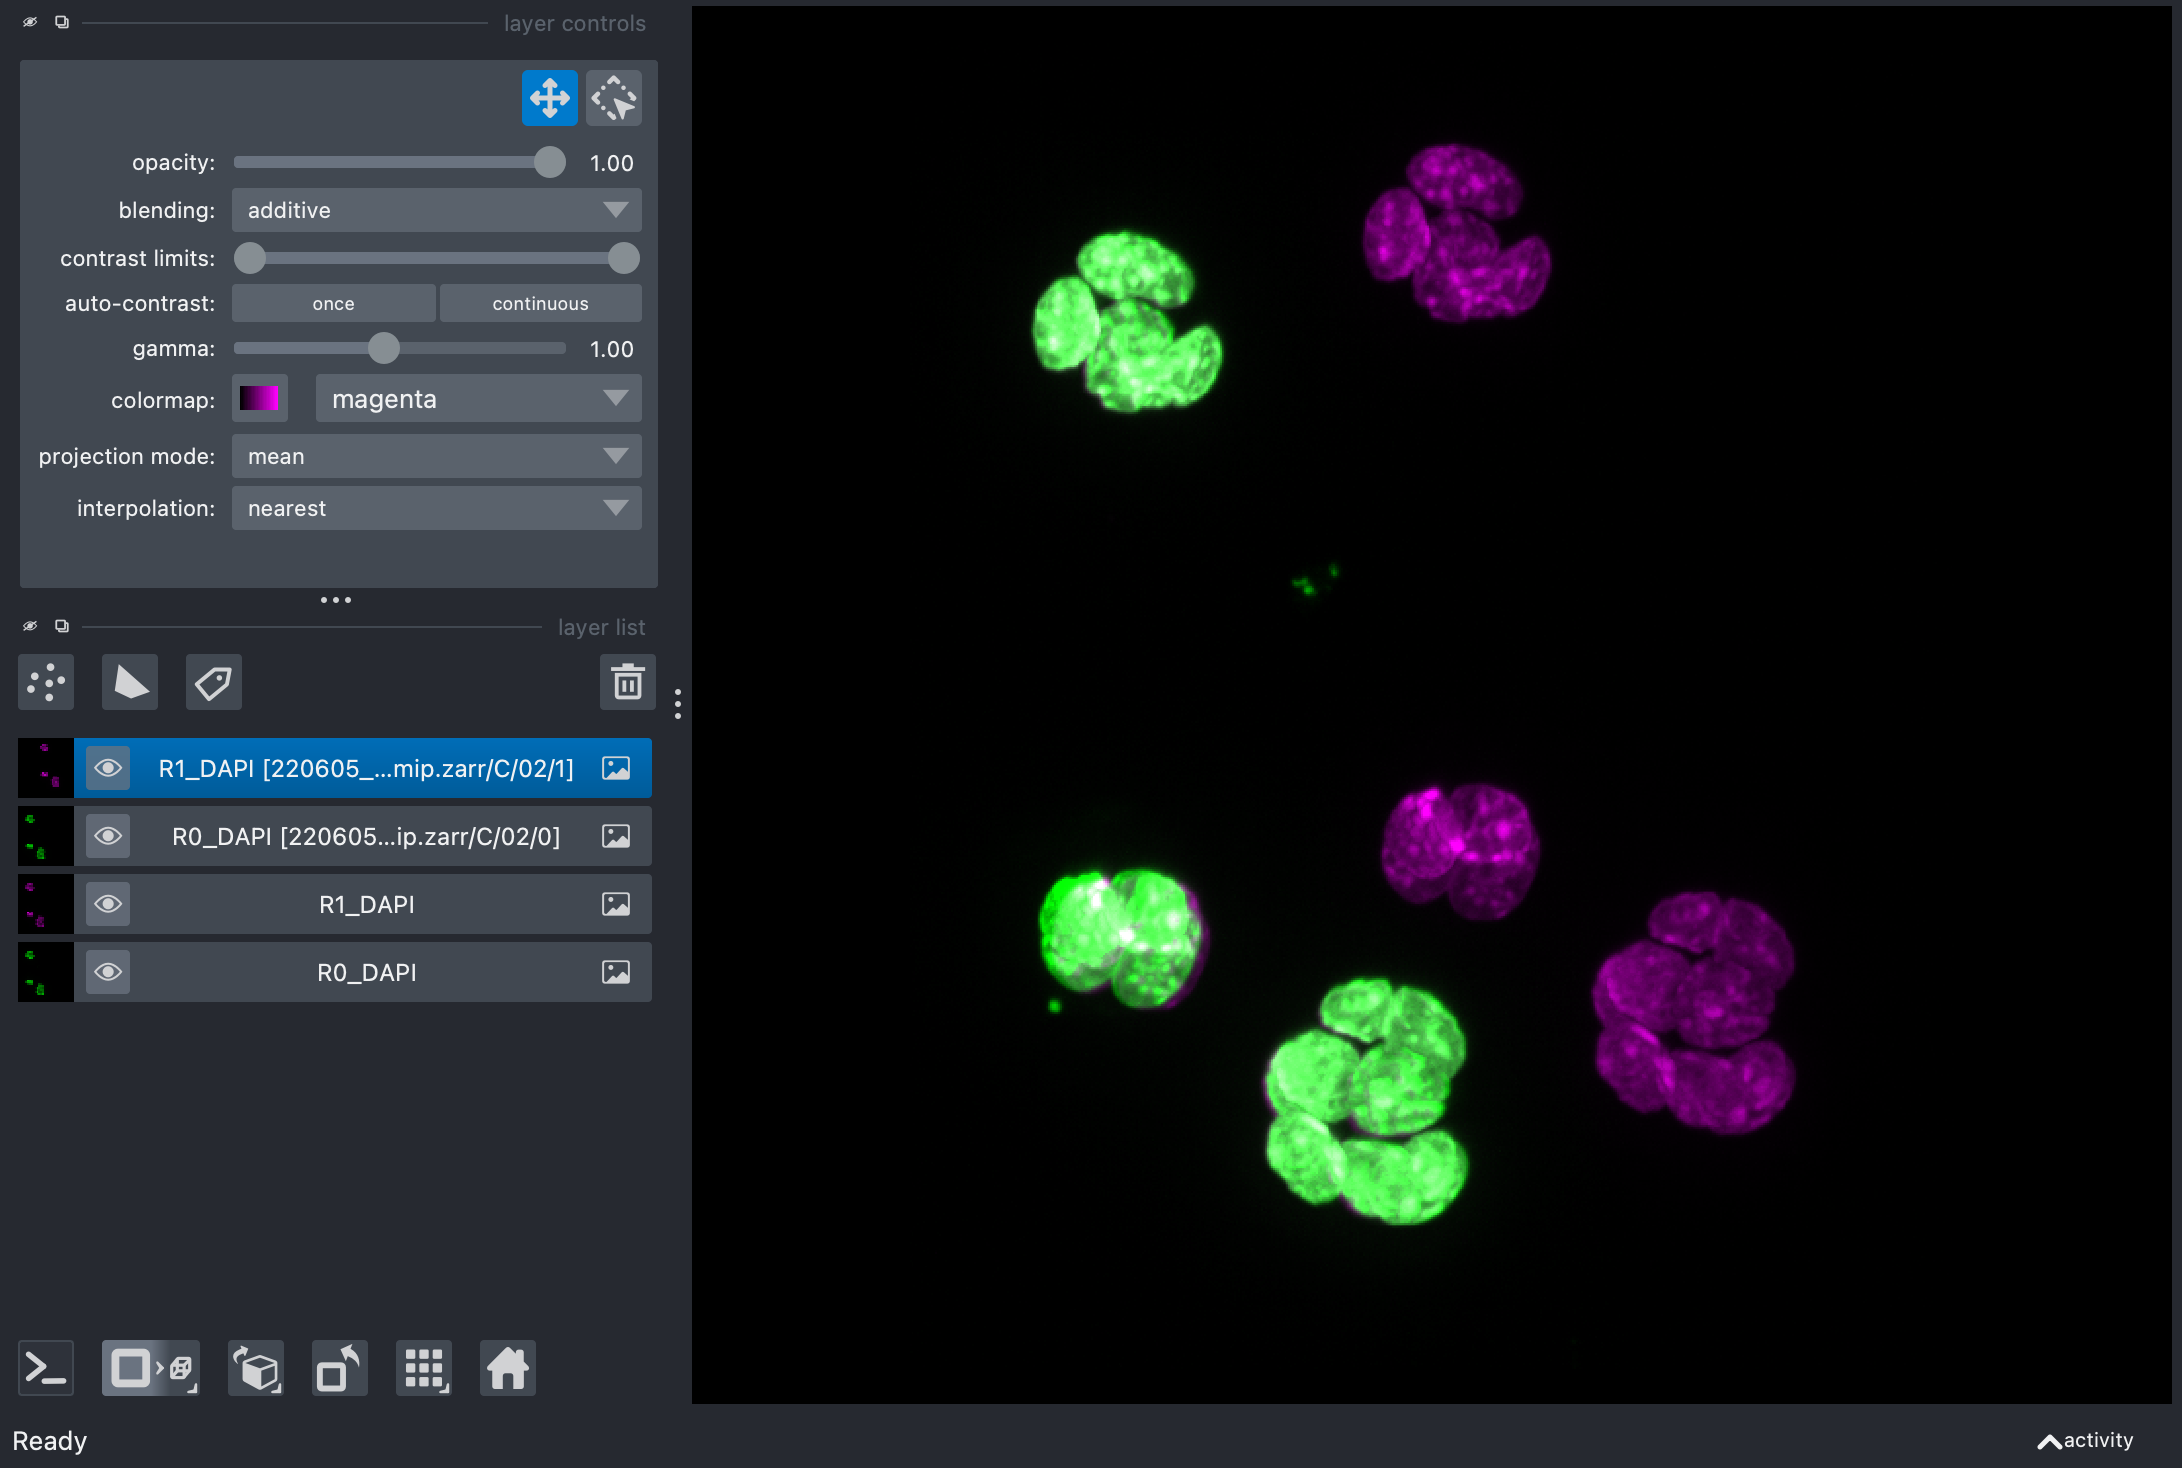

In [17]:
from napari.utils import nbscreenshot


def overlay(viewer):
    """Cycle 0 green, cycle 1 magenta, blended."""
    for layer in viewer.layers:
        layer.colormap = "green" if layer.name.startswith("R0") else "magenta"
        layer.blending = "additive"
    viewer.reset_view()
    return nbscreenshot(viewer)


before = calculate.show()
overlay(before)

## 2. Find the consensus region

The next task runs on the images the previous one returned. It writes the `FOV_ROI_table_registered` table: the part of each FOV that all cycles cover.

In [18]:
consensus.run(calculate.zarr_urls)

=== setup on 2 image(s)
$ /opt/homebrew/bin/pixi run --frozen --manifest-path /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/pyproject.toml python /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/fractal_tasks_core/init_registration_consensus.py --args-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Find Registration Consensus/setup.args.json --out-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Find Registration Consensus/setup.out.json
2026-11-05 15:13:37,748; run_fractal_task; INFO; START init_registration_consensus task
2026-11-05 15:13:37,748; init_registration_consensus; INFO; Running `init_registration_consensus` for zarr_urls=['/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/0', '/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/1']
2026-11-05 15:13:37,750; init_registration_consensus; INFO; Found well Well(#images: 2) wit

<Task 'Find Registration Consensus' (fractal-tasks-core 2.1.0, compound)>

## 3. Apply the registration

`registered_roi_table` names the table from step 2. The task shifts each cycle onto the reference, masks the area outside the consensus region, and with `overwrite_input=True` (the default) replaces the image data. It also aligns the image's label images (`register_labels=True`).

With `overwrite_input=False` the aligned images go next to the originals (`0_registered`, ...) instead. These are added to the well as further images of the same cycles, and the registration tasks then no longer run on that well.

In [19]:
apply_registration.run(
    consensus.zarr_urls,
    registered_roi_table="FOV_ROI_table_registered",
)
apply_registration.zarr_urls


=== image 1/2: 220605_151046_mip.zarr/C/02/0
$ /opt/homebrew/bin/pixi run --frozen --manifest-path /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/pyproject.toml python /Users/dakren/.napari_workflow_tasks/envs/fractal-tasks-core/2.1.0/source/fractal_tasks_core-2.1.0/fractal_tasks_core/apply_registration_to_image.py --args-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Apply Registration to Image/image_1.args.json --out-json /Users/dakren/.napari_workflow_tasks/tasks/fractal-tasks-core/2.1.0/Apply Registration to Image/image_1.out.json
2026-11-05 15:13:41,164; run_fractal_task; INFO; START apply_registration_to_image task
2026-11-05 15:13:41,164; apply_registration_to_image; INFO; Running `apply_registration_to_image` on zarr_url='/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/0', registered_roi_table='FOV_ROI_table_registered' and reference_acquisition=0. Using overwrite_input=True and register_labels=T

['/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/0',
 '/Users/dakren/Downloads/220605_151046_mip.zarr/C/02/1']

### After: the aligned cycles

`show()` adds to the current napari viewer, which still shows the unaligned images. A new viewer shows only the aligned ones:

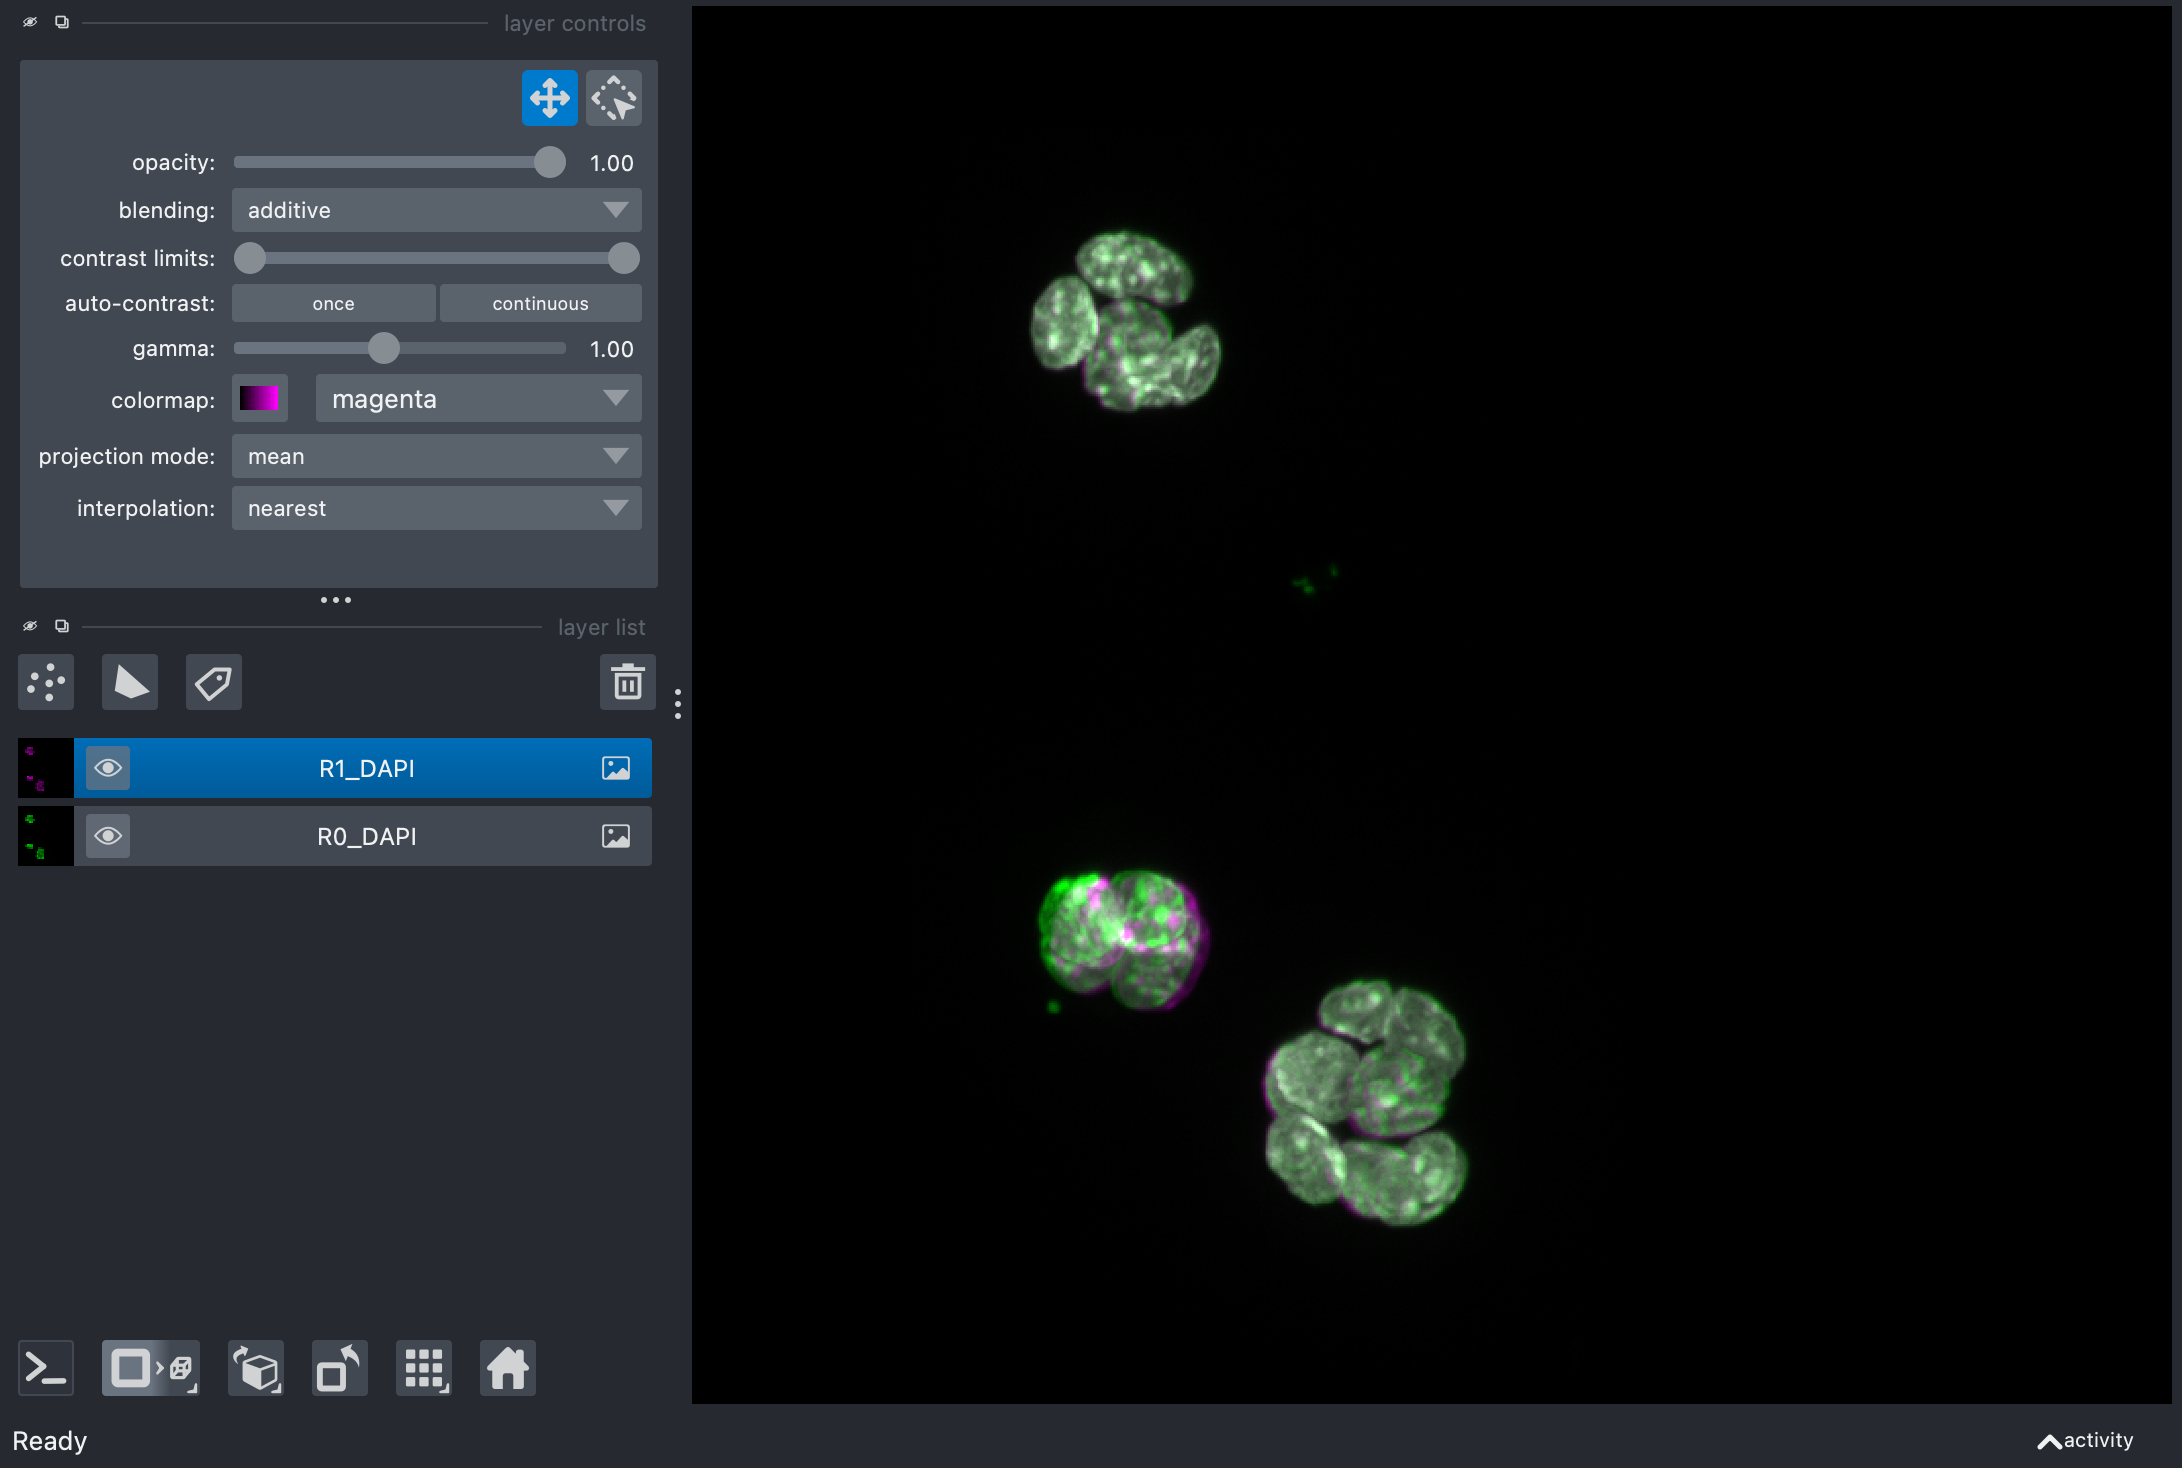

In [20]:
import napari

after = apply_registration.show(napari.Viewer())
overlay(after)